Всем привет! Сегодня вы впервые попробуете написать свою собственную нейронную сеть и попробовать ее обучить. Мы будем работать с картинками, но пока что не совсем тем способом, которым лучше всего это делать, но должно получиться неплохо.

Будем работать с [датасетом](https://github.com/rois-codh/kmnist) `Kuzushiji-MNIST` (`KMNIST`). Это рукописные буквы, изображения имеют размер (28, 28, 1) и разделены на 10 классов, по ссылке можно прочитать подробнее.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output

## Загрузка данных

Сейчас мы будем использовать встроенные данные, но в реальности приходится писать свой класс для датасета (Dataset), у которого реализовывать несколько обязательных методов (напр, `__getitem__`), но это обсудим уже потом.

In [2]:
import torchvision
from torchvision.datasets import KMNIST


# Превращает картинки в тензоры
transform = torchvision.transforms.Compose(
    [torchvision.transforms.ToTensor()])

# Загрузим данные (в переменных лежат объекты типа `Dataset`)
# В аргумент `transform` мы передаем необходимые трансформации (ToTensor)
trainset = KMNIST(root="./KMNIST", train=True, download=True, transform=transform)
testset = KMNIST(root="./KMNIST", train=False, download=True, transform=transform)

clear_output()

Определим даталоадеры, они нужны, чтобы реализовывать стохастический градиентный спуск (то есть мы не хотим считывать в оперативную память все картинки сразу, а делать это батчами).

In [3]:
from torch.utils.data import DataLoader


# Можно оставить таким
batch_size = 256

trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

Подумайте, как может влиять на скорость обучения параметр `batch_size`, почему вы так считаете?

**Ответ:**

С увеличением размера батча скорость обучения должна повышаться.

Логика такая: увеличиваем размер батча -> сокращаем количество батчей -> сокращаем количество итераций в эпоху. Из-за сокращения времени одной эпохи мы достигаем увеличения скорости обучения.

Посмотрим на какую-нибудь картинку:

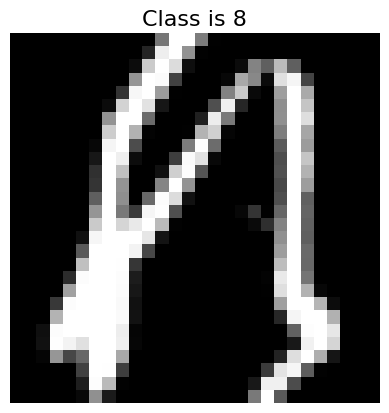

In [4]:
plt.imshow(trainset[0][0].view(28, 28).numpy(), cmap="gray")
plt.axis("off")
plt.title(f"Class is {trainset[0][1]}", fontsize=16);

### Задание 1. Смотрим на картинки

**2** балла

Нарисуйте на одном графике изображения всех 10 классов:

⣿⣿⣿⣿⣿⣿⠿⢋⣥⣴⣶⣶⣶⣬⣙⠻⠟⣋⣭⣭⣭⣭⡙⠻⣿⣿⣿⣿⣿
⣿⣿⣿⣿⡿⢋⣴⣿⣿⠿⢟⣛⣛⣛⠿⢷⡹⣿⣿⣿⣿⣿⣿⣆⠹⣿⣿⣿⣿
⣿⣿⣿⡿⢁⣾⣿⣿⣴⣿⣿⣿⣿⠿⠿⠷⠥⠱⣶⣶⣶⣶⡶⠮⠤⣌⡙⢿⣿
⣿⡿⢛⡁⣾⣿⣿⣿⡿⢟⡫⢕⣪⡭⠥⢭⣭⣉⡂⣉⡒⣤⡭⡉⠩⣥⣰⠂⠹
⡟⢠⣿⣱⣿⣿⣿⣏⣛⢲⣾⣿⠃⠄⠐⠈⣿⣿⣿⣿⣿⣿⠄⠁⠃⢸⣿⣿⡧
⢠⣿⣿⣿⣿⣿⣿⣿⣿⣇⣊⠙⠳⠤⠤⠾⣟⠛⠍⣹⣛⣛⣢⣀⣠⣛⡯⢉⣰
⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣷⡶⠶⢒⣠⣼⣿⣿⣛⠻⠛⢛⣛⠉⣴⣿⣿
⣿⣿⣿⣿⣿⣿⣿⡿⢛⡛⢿⣿⣿⣶⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣷⡈⢿⣿
⣿⣿⣿⣿⣿⣿⣿⠸⣿⡻⢷⣍⣛⠻⠿⠿⣿⣿⣿⣿⣿⣿⣿⣿⣿⠿⢇⡘⣿
⣿⣿⣿⣿⣿⣿⣿⣷⣝⠻⠶⣬⣍⣛⣛⠓⠶⠶⠶⠤⠬⠭⠤⠶⠶⠞⠛⣡⣿
⢿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣷⣶⣬⣭⣍⣙⣛⣛⣛⠛⠛⠛⠿⠿⠿⠛⣠⣿⣿
⣦⣈⠉⢛⠻⠿⠿⢿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡿⠿⠛⣁⣴⣾⣿⣿⣿⣿
⣿⣿⣿⣶⣮⣭⣁⣒⣒⣒⠂⠠⠬⠭⠭⠭⢀⣀⣠⣄⡘⠿⣿⣿⣿⣿⣿⣿⣿
⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⣦⡈⢿⣿⣿⣿⣿⣿





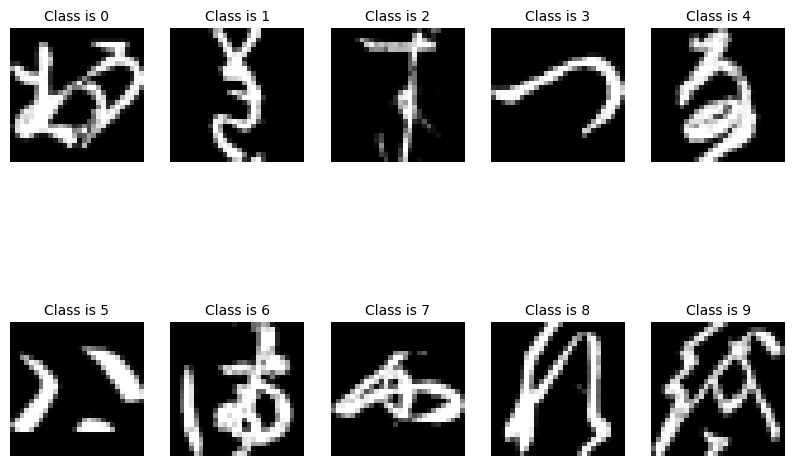

In [5]:
fig = plt.figure(figsize=(10, 7))
for number_class in range(10):
    plt.subplot(2, 5, number_class + 1)
    for image, label in trainset:
      if label == number_class:
        image = image.view(28, 28).numpy()
        plt.imshow(image, cmap="gray")
        plt.axis("off")
        plt.title(f"Class is {number_class}", fontsize=10)
        break

### Задание 2. Строим свой первый MLP

**4** балла

MLP (multilayer perceptron) или нейронная сеть из полносвязных (линейных) слоев, это мы уже знаем.

Опишите структуру сети: 3 полносвязных слоя + функции активации на ваш выбор. **Подумайте** про активацию после последнего слоя!

Сеть на выходе 1 слоя должна иметь 256 признаков, на выходе из 2 128 признаков, на выходе из последнего столько, сколько у вас классов.

https://pytorch.org/docs/stable/nn.html?highlight=activation#non-linear-activations-weighted-sum-nonlinearity

In [6]:
import torch.nn as nn
import torch.nn.functional as F

class FCNet(nn.Module):
    def __init__(self):
        super().__init__() #  это надо помнить!
        ## YOUR CODE HERE
        self.fc1 = nn.Linear(in_features=28*28, out_features=256)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)


    def forward(self, x):  # Forward вызывается внутри метода __call__ родительского класса
        ## x -> тензор размерности (BATCH_SIZE, N_CHANNELS, WIDTH, HEIGHT)
        ## надо подумать над тем, что у нас полносвязные слои принимают векторы
        ## YOUR CODE HERE
        x = x.view(-1, 28*28)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        logits = self.fc3(x)
        return logits

Сколько обучаемых параметров у вашей модели (весов и смещений)?

**Ответ:**

Кол-во параметров:

1 слой: 28 * 28 * 256 + 256 = 200960

2 слой: 256 * 128 + 128 = 32896

3 слой: 128 * 10 + 10 = 1290

Всего: 235146

### Задание 3. Напишите код для обучения модели

**5** баллов

Можно (и нужно) подглядывать в код семинара по пайторчу. Вам нужно создать модель, определить функцию потерь и оптимизатор (начнем с `SGD`). Дальше нужно обучать модель, при помощи тренировочного `Dataloader'a` и считать лосс на тренировочном и тестовом `Dataloader'ах`.

Напишем функцию для рассчета `accuracy`:

In [7]:
def get_accuracy(model, dataloader):
    """
    model - обученная нейронная сеть
    dataloader - даталоадер, на котором вы хотите посчитать accuracy
    """
    correct = 0
    total = 0
    with torch.no_grad(): # Тензоры внутри этого блока будут иметь requires_grad=False
        for images, labels in dataloader:
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = correct / total

    return accuracy

#### Основной цикл обучения

Этот код можно (и зачастую нужно) выносить в отдельную функцию, но пока что можете это не делать, все по желанию)

In [8]:
# Создадим объект модели
fc_net = FCNet()
# Определим функцию потерь
loss_function = nn.CrossEntropyLoss()
# Создадим оптимизатор для нашей сети
lr = 0.001 # скорость обучения
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

Напишите цикл обучения. Для начала хватит 10 эпох. Какое значение `accuracy` на тестовой выборке удалось получить?

In [9]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader: # Получаем батч тренировочных картинок
        optimizer.zero_grad() # чтобы не было как в лог регрессии, когда мы не обнуляли градиенты
        outputs = fc_net(images) # делаем предсказания
        loss = loss_function(outputs, labels) # считаем лосс
        loss.backward() # считаем градиенты
        optimizer.step() # делаем шаг градиентного спуска

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.9210
Epoch=2 loss=0.4426
Epoch=3 loss=0.3459
Epoch=4 loss=0.2860
Epoch=5 loss=0.2439
Epoch=6 loss=0.2122
Epoch=7 loss=0.1850
Epoch=8 loss=0.1637
Epoch=9 loss=0.1437
Epoch=10 loss=0.1271
CPU times: user 35.7 s, sys: 2.52 s, total: 38.2 s
Wall time: 1min 41s


Визуализируем проделанные шаги спуска в каждой эпохе

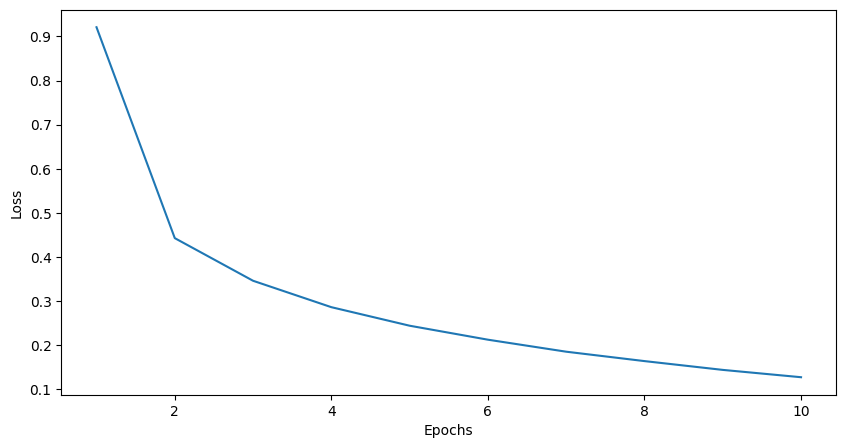

In [10]:
plt.figure(figsize=(10, 5))
plt.plot([i+1 for i in range(n_epochs)], loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [11]:
accuracy = get_accuracy(fc_net, testloader)
print(f'The obtained accuracy score: {accuracy}')

The obtained accuracy score: 0.8745


### Задание 4. Изучение влияния нормализации

**3** балла

Вы могли заметить, что мы забыли провести нормализацию наших данных, а для нейронных сетей это может быть очень критично.

Нормализуйте данные.

* Подсчитайте среднее значение и стандартное отклонение интенсивности пикселей для всех тренировочных данных
* Нормализуйте данные с использованием этих параметров (используйте трансформацию `Normalize`)


Оцените влияние нормировки данных.

In [12]:
sum_mean = 0
sum_std = 0
for image, _ in trainset:
  sum_mean += float(image.mean())
  sum_std += float(image.std())

mean = sum_mean / len(trainset)
std = sum_std / len(trainset)
print(f'Mean: {mean}')
print(f'Standard deviation: {std}')

transform_with_norm = torchvision.transforms.Compose([
                torchvision.transforms.ToTensor(),
                torchvision.transforms.Normalize(mean, std)
            ])

trainset.transform = transform_with_norm
testset.transform = transform_with_norm

Mean: 0.19176215064801896
Standard deviation: 0.3385266238119453


In [14]:
fc_net = FCNet()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

In [15]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.6855
Epoch=2 loss=0.3026
Epoch=3 loss=0.2219
Epoch=4 loss=0.1730
Epoch=5 loss=0.1380
Epoch=6 loss=0.1122
Epoch=7 loss=0.0923
Epoch=8 loss=0.0756
Epoch=9 loss=0.0604
Epoch=10 loss=0.0501
CPU times: user 36.4 s, sys: 2.82 s, total: 39.2 s
Wall time: 2min 42s


In [16]:
accuracy_relu = get_accuracy(fc_net, testloader)
print(f'The obtained accuracy after normalization: {accuracy_relu}')

The obtained accuracy after normalization: 0.8938


Как изменилась `accuracy` после нормализации?

**Ответ**

Нормализация сильно повлияла на полученный результат - значения accuracy стали выше

### Задание 5. Изучение влияния функции активации

**3** балла

Исследуйте влияние функций активации на скорость обучения и точность предсказаний модели.

Используйте три функции:

* [Sigmoid](https://pytorch.org/docs/stable/nn.functional.html#sigmoid)
* [GELU](https://pytorch.org/docs/stable/nn.functional.html#gelu)
* [Tanh](https://pytorch.org/docs/stable/generated/torch.nn.Tanh.html#torch.nn.Tanh)

#### Sigmoid

In [17]:
## YOUR CODE HERE
class FCNet_sig(nn.Module):
    def __init__(self):
      super().__init__()
      self.fc1 = nn.Linear(in_features=28*28, out_features=256)
      self.fc2 = nn.Linear(in_features=256, out_features=128)
      self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = self.fc1(x)
        x = F.sigmoid(x)  # Sigmoid
        x = self.fc2(x)
        x = F.sigmoid(x)
        logits = self.fc3(x)
        return logits

In [18]:
fc_net = FCNet_sig()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

In [19]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=1.5299
Epoch=2 loss=0.7572
Epoch=3 loss=0.5481
Epoch=4 loss=0.4435
Epoch=5 loss=0.3720
Epoch=6 loss=0.3169
Epoch=7 loss=0.2737
Epoch=8 loss=0.2387
Epoch=9 loss=0.2089
Epoch=10 loss=0.1837
CPU times: user 36.3 s, sys: 2.89 s, total: 39.1 s
Wall time: 2min 43s


In [21]:
accuracy_sig = get_accuracy(fc_net, testloader)
print(f'Accuracy score for sigmoid activation function: {accuracy_sig}')

Accuracy score for sigmoid activation function: 0.8529


#### GELU

In [22]:
## YOUR CODE HERE
class FCNet_gelu(nn.Module):
    def __init__(self):
      super().__init__()
      self.fc1 = nn.Linear(in_features=28*28, out_features=256)
      self.fc2 = nn.Linear(in_features=256, out_features=128)
      self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = self.fc1(x)
        x = F.gelu(x)  # GELU
        x = self.fc2(x)
        x = F.gelu(x)
        logits = self.fc3(x)
        return logits

In [23]:
fc_net = FCNet_gelu()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

In [24]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.6647
Epoch=2 loss=0.2875
Epoch=3 loss=0.2084
Epoch=4 loss=0.1599
Epoch=5 loss=0.1267
Epoch=6 loss=0.1024
Epoch=7 loss=0.0823
Epoch=8 loss=0.0664
Epoch=9 loss=0.0543
Epoch=10 loss=0.0426
CPU times: user 38.8 s, sys: 2.81 s, total: 41.6 s
Wall time: 3min 49s


In [25]:
accuracy_gelu = get_accuracy(fc_net, testloader)
print(f'Accuracy score for GELU activation function: {accuracy_gelu}')

Accuracy score for GELU activation function: 0.9018


#### Tanh

In [26]:
## YOUR CODE HERE
class FCNet_tanh(nn.Module):
    def __init__(self):
      super().__init__()
      self.fc1 = nn.Linear(in_features=28*28, out_features=256)
      self.fc2 = nn.Linear(in_features=256, out_features=128)
      self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = self.fc1(x)
        x = F.tanh(x)  # tanh
        x = self.fc2(x)
        x = F.tanh(x)
        logits = self.fc3(x)
        return logits

In [28]:
fc_net = FCNet_tanh()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

In [29]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.7681
Epoch=2 loss=0.3844
Epoch=3 loss=0.2616
Epoch=4 loss=0.1873
Epoch=5 loss=0.1389
Epoch=6 loss=0.1041
Epoch=7 loss=0.0779
Epoch=8 loss=0.0593
Epoch=9 loss=0.0431
Epoch=10 loss=0.0312
CPU times: user 36.2 s, sys: 2.87 s, total: 39 s
Wall time: 2min 41s


In [30]:
accuracy_tanh = get_accuracy(fc_net, testloader)
print(f'Accuracy score for Tahn activation function: {accuracy_tanh}')

Accuracy score for Tahn activation function: 0.898


In [31]:
scores = {'Sigmoid': accuracy_sig, 'GELU': accuracy_gelu, 'Tahn': accuracy_tanh}

for score in scores.items():
  name, value = score
  print(f'The {name} activation function has {value} accuracy score')

The Sigmoid activation function has 0.8529 accuracy score
The GELU activation function has 0.9018 accuracy score
The Tahn activation function has 0.898 accuracy score


С использованием какой функции активации удалось досчить наибольшей `accuracy`?

**Ответ**

Наилучшие показатели `accuracy` были получены при использовании функции функции GELU.

По скорости обучения она выполнялась дольше всех.

### Задание 6. Другие оптимизаторы

**4** балла

Исследуйте влияние оптимизаторов на скорость обучения и точность предсказаний модели.

Попробуйте следующие:

* [Adam](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)
* [RMSprop](https://pytorch.org/docs/stable/generated/torch.optim.RMSprop.html#torch.optim.RMSprop)
* [Adagrad](https://pytorch.org/docs/stable/generated/torch.optim.Adagrad.html#torch.optim.Adagrad)

Вам нужно снова обучить 3 модели и сравнить их перформанс (функцию активации используйте ту, которая показала себя лучше всего).

Оптимизатор Adam, который позволяет в градиентном спуске менять показатели learning rate, мы использовали на всех предыдущих шагах. Сравниваю его результаты с двумя другими предложенными оптимизаторами.

#### RMSprop

In [32]:
fc_net = FCNet_gelu()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.RMSprop(fc_net.parameters(), lr=3e-4)

In [33]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.4376
Epoch=2 loss=0.2364
Epoch=3 loss=0.1737
Epoch=4 loss=0.1343
Epoch=5 loss=0.1050
Epoch=6 loss=0.0832
Epoch=7 loss=0.0663
Epoch=8 loss=0.0526
Epoch=9 loss=0.0406
Epoch=10 loss=0.0313
CPU times: user 35.3 s, sys: 2.75 s, total: 38.1 s
Wall time: 3min 21s


In [34]:
accuracy_rms = get_accuracy(fc_net, testloader)
print(f'Accuracy score for RMSprop optimizer: {accuracy_rms}')

Accuracy score for RMSprop optimizer: 0.8991


#### Adagrad

In [37]:
fc_net = FCNet_gelu()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adagrad(fc_net.parameters(), lr=3e-4)

In [38]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=1.3358
Epoch=2 loss=0.8078
Epoch=3 loss=0.6820
Epoch=4 loss=0.6201
Epoch=5 loss=0.5807
Epoch=6 loss=0.5523
Epoch=7 loss=0.5311
Epoch=8 loss=0.5131
Epoch=9 loss=0.4987
Epoch=10 loss=0.4854
CPU times: user 34.5 s, sys: 2.75 s, total: 37.3 s
Wall time: 2min 40s


In [39]:
accuracy_adag = get_accuracy(fc_net, testloader)
print(f'Accuracy score for Adagrad optimizer: {accuracy_adag}')

Accuracy score for Adagrad optimizer: 0.7223


In [40]:
scores = {'Adam': accuracy_gelu, 'RMSprop': accuracy_rms, 'Adagrad': accuracy_adag}

for score in scores.items():
  name, value = score
  print(f'The {name} optimizer has {value} accuracy score')

The Adam optimizer has 0.9018 accuracy score
The RMSprop optimizer has 0.8991 accuracy score
The Adagrad optimizer has 0.7223 accuracy score


**Ответ**

Наилучшие показатели достигнуты у исходного Adam оптимизатора.

Использование Adagrad значительно снижает качество предсказания.

### Задание 7. Реализация ReLU

**4** балла

Самостоятельно реализуйте функцию активации ReLU.
Замените в уже обученной модели функцию активации на вашу. Убедитесь что ничего не изменилась.

In [41]:
class CustomReLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        # YOUR CODE HERE
        # если элемент x < 0, то 0, если >= 0, то x
        x = torch.where(x < 0, 0, x)
        return x

Заново обучите модель и проверьте правильность реализации `CustomReLU`.

In [42]:
class FCNet_crelu(nn.Module):
    def __init__(self):
      super().__init__()
      self.fc1 = nn.Linear(in_features=28*28, out_features=256)
      self.fc2 = nn.Linear(in_features=256, out_features=128)
      self.fc3 = nn.Linear(in_features=128, out_features=10)
      self.activation = CustomReLU()

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = self.fc1(x)
        x = self.activation(x)  # CustomReLU
        x = self.fc2(x)
        x = self.activation(x)
        logits = self.fc3(x)
        return logits

In [43]:
fc_net = FCNet_crelu()
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc_net.parameters(), lr=3e-4)

In [44]:
%%time
n_epochs = 10
loss_history = []

## YOUR CODE HERE
for epoch in range(n_epochs):
    epoch_loss = 0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = fc_net(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    loss_history.append(epoch_loss/len(trainloader))

    print(f"Epoch={epoch+1} loss={loss_history[epoch]:.4f}")

Epoch=1 loss=0.6796
Epoch=2 loss=0.3006
Epoch=3 loss=0.2208
Epoch=4 loss=0.1721
Epoch=5 loss=0.1381
Epoch=6 loss=0.1113
Epoch=7 loss=0.0923
Epoch=8 loss=0.0751
Epoch=9 loss=0.0613
Epoch=10 loss=0.0498
CPU times: user 38.1 s, sys: 2.8 s, total: 40.9 s
Wall time: 2min 43s


In [45]:
accuracy_cust_relu = get_accuracy(fc_net, testloader)
print(f'Accuracy score for Custom_ReLU: {accuracy_cust_relu}')

Accuracy score for Custom_ReLU: 0.9


In [46]:
print(f'Accuracy score for standard ReLU: {accuracy_relu}')

Accuracy score for standard ReLU: 0.8938


Для кастомной ReLU значения `accuracy` получились чуть больше

Скорее всего существует определенная вариативность при подсчете каждого нового значения данной метрики

### Задание 8. Генерация картинок

**3** балла

Придумайте 3 предложения и сгенерируйте при помощи них 3 картинки, используя телеграм бота [ruDALLE](https://t.me/sber_rudalle_xl_bot). Прикрепите сюда ваши картины.

Использовала Gencraft

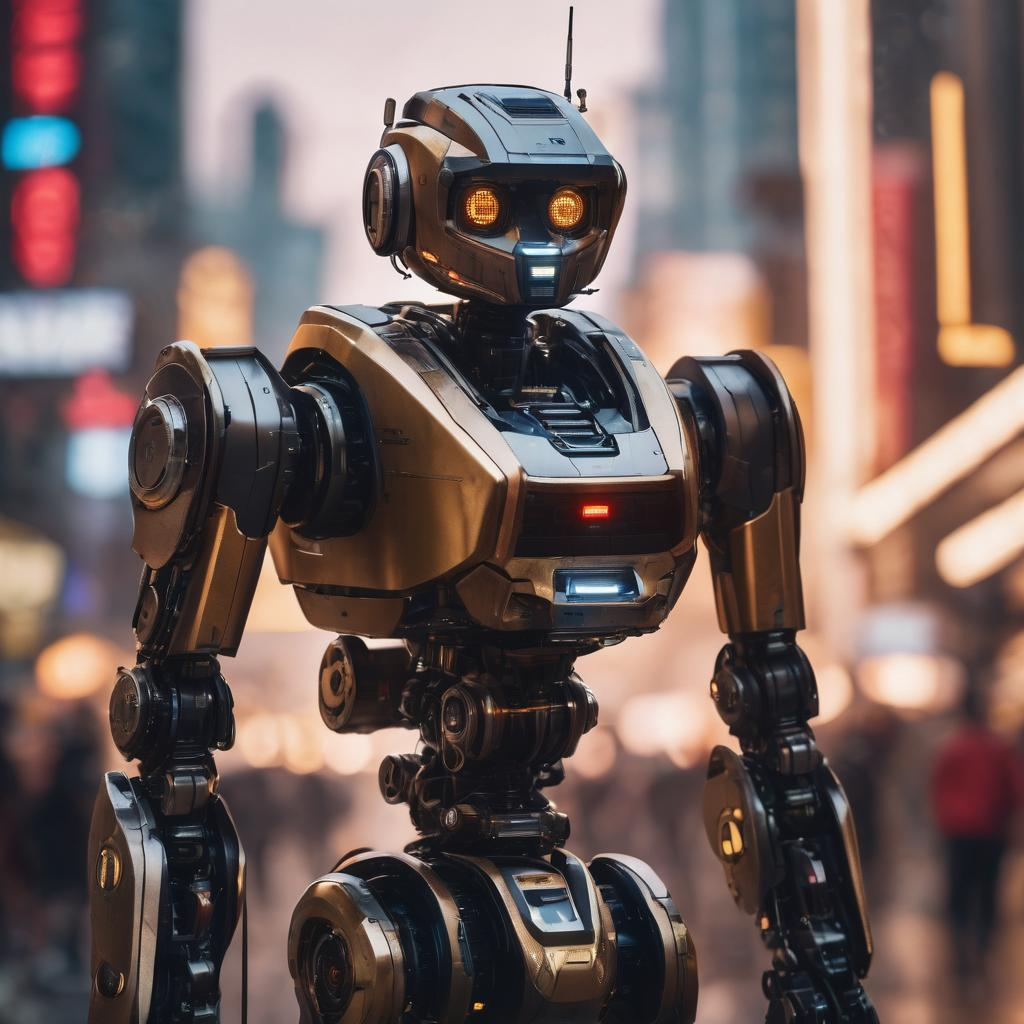

In [1]:
from IPython.display import Image

Image(filename='../images/image_robot.jpeg') 

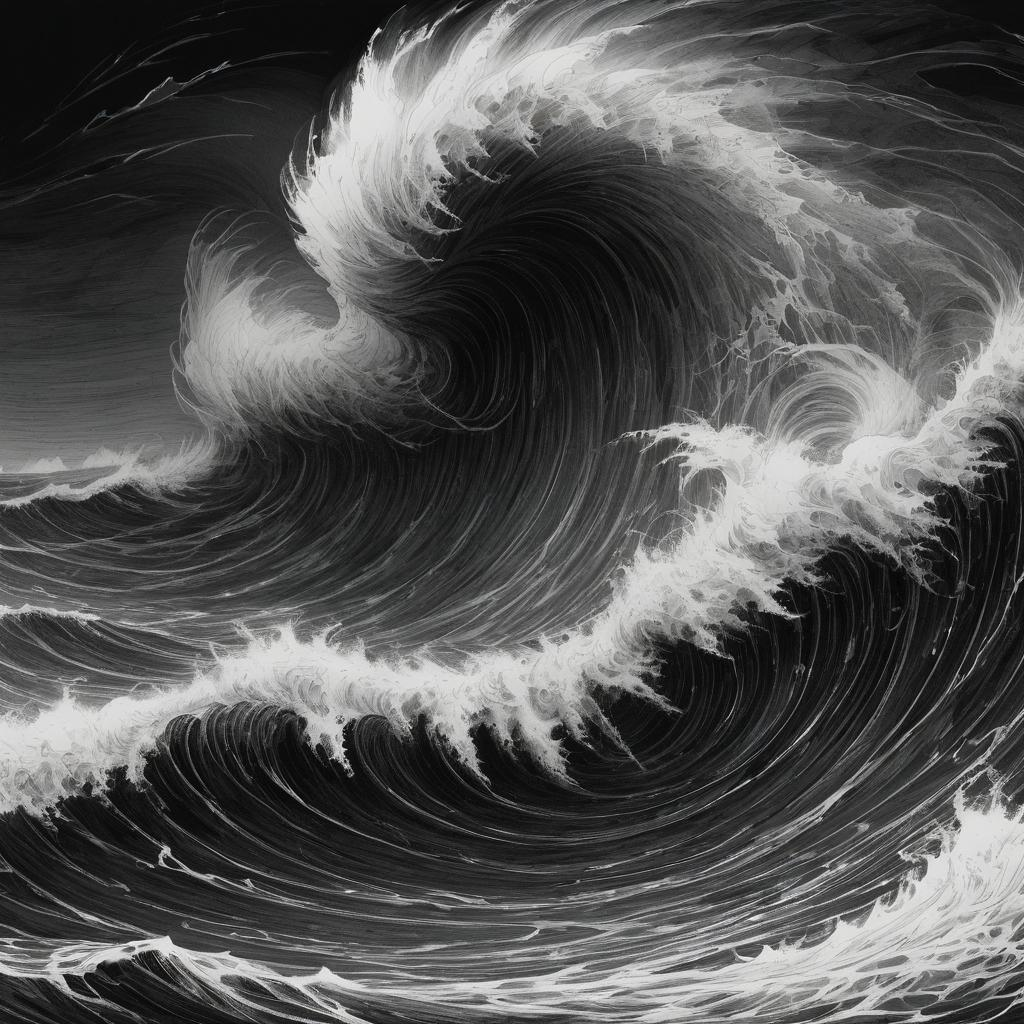

In [2]:
Image(filename='../images/image_sea.jpeg') 

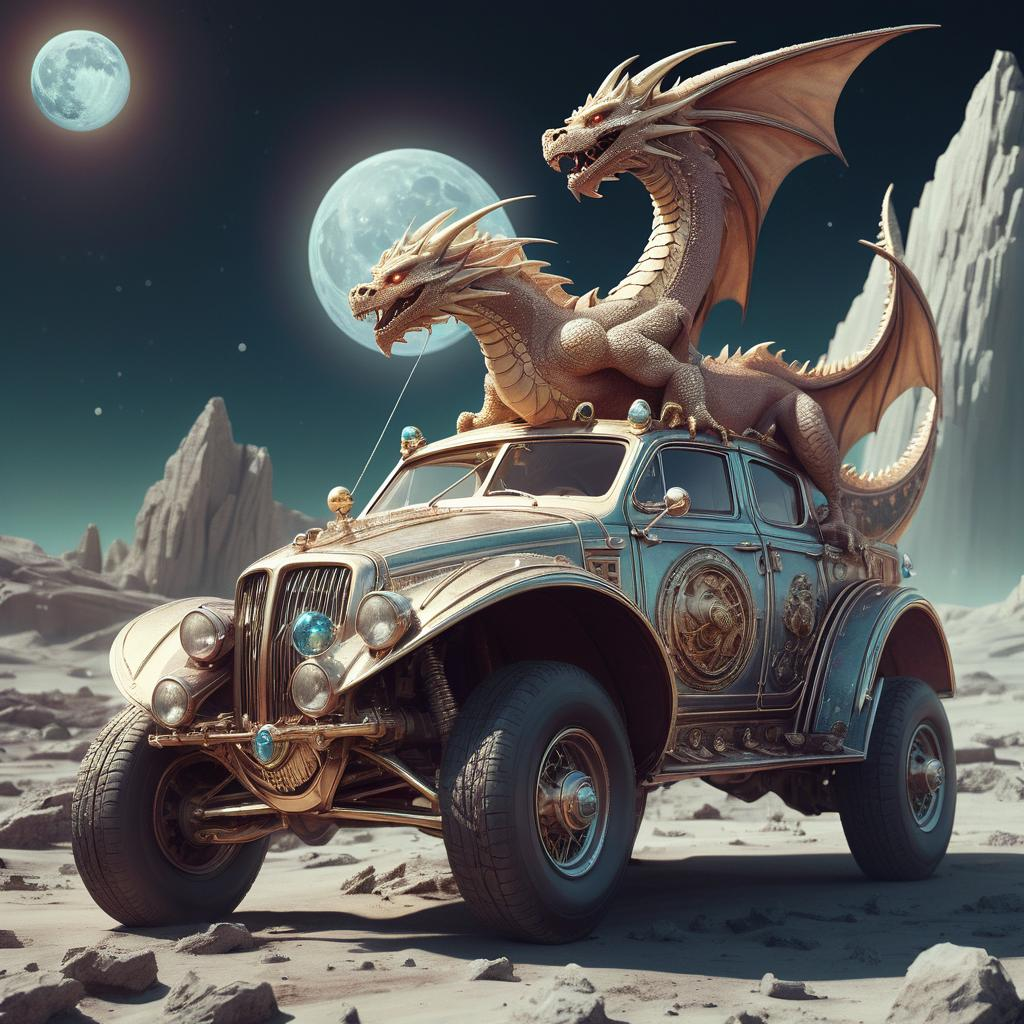

In [3]:
Image(filename='../images/image_auto.jpeg') 